In [1]:
pip install medmnist

Note: you may need to restart the kernel to use updated packages.


In [2]:
from tqdm import tqdm
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torch.utils.data as data
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import medmnist
from medmnist import INFO, Evaluator

data_flag = 'chestmnist'
info = INFO[data_flag]
task = info['task']
n_channels = info['n_channels']
n_classes = len(info['label'])
DataClass = getattr(medmnist, info['python_class'])

data_transform = transforms.Compose([transforms.ToTensor()])

train_dataset = DataClass(split='train', transform = data_transform, download = True)
test_dataset = DataClass(split='test', transform = data_transform, download = True)

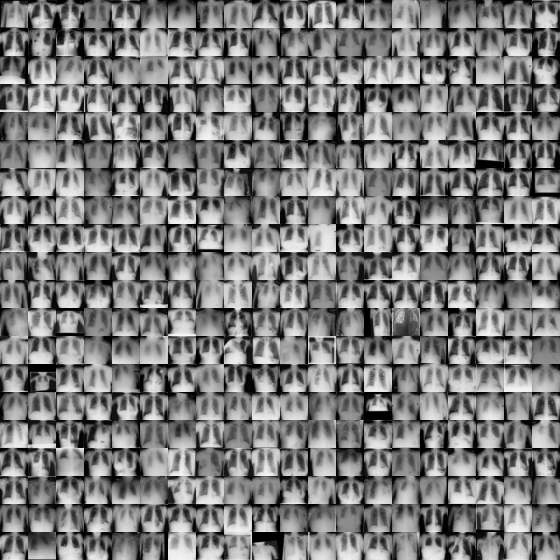

In [3]:
train_loader = data.DataLoader(dataset=train_dataset, batch_size=100, shuffle=True)
test_loader = data.DataLoader(dataset=test_dataset, batch_size=100, shuffle=False)

train_dataset.montage(length=20)

In [4]:
kernel_size = 5

class autoencoder(nn.Module):
    def __init__(self):
        super().__init__()

        self.conv1 = nn.Conv2d(1, 6, kernel_size)
        self.conv2 = nn.Conv2d(6, 12, kernel_size)
        self.pool  = nn.MaxPool2d(2, 2)
        self.iconv1 = nn.ConvTranspose2d(12, 6, kernel_size+1, stride = 2)
        self.iconv2 = nn.ConvTranspose2d(6, 1, kernel_size+1, stride = 2)

    def encode(self, x):
        x = F.relu(self.conv1(x))
        x = self.pool(x)
        x = F.relu(self.conv2(x))
        x = self.pool(x)
        return x

    def decode(self, x):
        x = F.relu(self.iconv1(x))
        ## sigmoid since pixel values are scaled between 0 and 1
        x = torch.sigmoid(self.iconv2(x))
        return x

    def forward(self, x):
        return self.decode(self.encode(x))

autoencoder = autoencoder()

In [5]:
tryItOut, tryItOutLabels = next(iter(train_loader))
print('input shape:', tryItOut.shape)

encoded = autoencoder.encode(tryItOut)
print('encoded (embedding) shape:', encoded.shape)

decoded = autoencoder.decode(encoded)
print('decoded shape:', decoded.shape)

fedForward = autoencoder.forward(tryItOut)
print('full forward pass shape:', fedForward.shape)

input shape: torch.Size([100, 1, 28, 28])
encoded (embedding) shape: torch.Size([100, 12, 4, 4])
decoded shape: torch.Size([100, 1, 28, 28])
full forward pass shape: torch.Size([100, 1, 28, 28])


In [6]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('using device:', device)

autoencoder = autoencoder.to(device)

optimizer = torch.optim.Adam(autoencoder.parameters(), lr = 0.001)
n_epochs = 5

autoencoder.train()

train_loss_by_epoch = []

for epoch in range(n_epochs):
    running_loss = 0.0
    n_batches = 0
    for images, labels in train_loader:
        images = images.to(device)
        optimizer.zero_grad()
        outputs = autoencoder.forward(images)
        loss = F.mse_loss(outputs, images)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
        n_batches += 1
    avg_loss = running_loss / n_batches
    train_loss_by_epoch.append(avg_loss)
    print(f'epoch {epoch+1}/{n_epochs}, average training loss: {avg_loss:.5f}')

using device: cpu
epoch 1/5, average training loss: 0.01625
epoch 2/5, average training loss: 0.00605
epoch 3/5, average training loss: 0.00495
epoch 4/5, average training loss: 0.00442
epoch 5/5, average training loss: 0.00411


In [7]:
def average_reconstruction_error(loader, model, device):
    model.eval()
    total_loss = 0.0
    n_batches = 0
    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            outputs = model.forward(images)
            loss = F.mse_loss(outputs, images)
            total_loss += loss.item()
            n_batches += 1
    return total_loss / n_batches

train_error = average_reconstruction_error(train_loader, autoencoder, device)
test_error = average_reconstruction_error(test_loader, autoencoder, device)

print('average training error (MSE):', train_error)
print('average testing error (MSE):', test_error)

average training error (MSE): 0.003978497510075949
average testing error (MSE): 0.003943331471333901


The average training MSE was 0.003978, and the average testing MSE was 0.003943. The errors were very close, suggesting that the autoencoder performed similarly on the training and testing images.

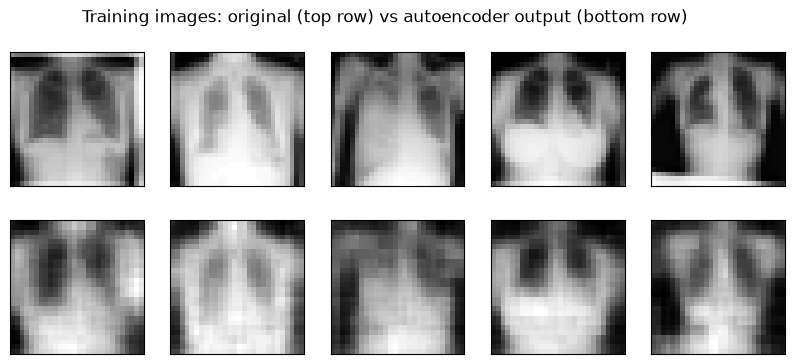

In [8]:
autoencoder.eval()
images, labels = next(iter(train_loader))
images = images.to(device)

with torch.no_grad():
    outputs = autoencoder.forward(images)

images = images.cpu().numpy()
outputs = outputs.cpu().numpy()

plt.figure(figsize=(10,4))
for i in range(5):
    plt.subplot(2, 5, i+1)
    plt.xticks([])
    plt.yticks([])
    plt.imshow(images[i,0,:,:], cmap = 'gray')

for i in range(5):
    plt.subplot(2, 5, i+6)
    plt.xticks([])
    plt.yticks([])
    plt.imshow(outputs[i,0,:,:], cmap = 'gray')

plt.suptitle('Training images: original (top row) vs autoencoder output (bottom row)')
plt.show()

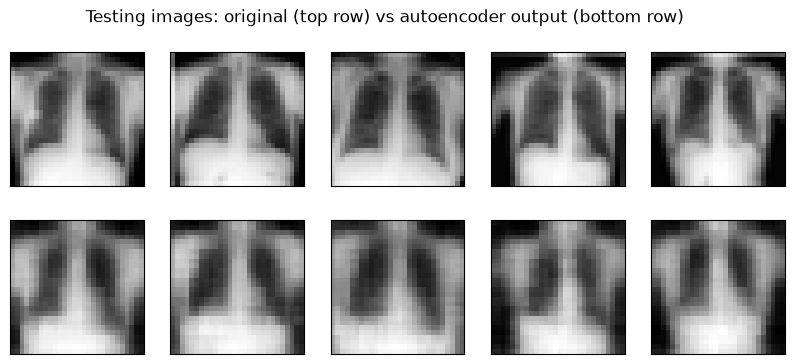

In [9]:
images, labels = next(iter(test_loader))
images = images.to(device)

with torch.no_grad():
    outputs = autoencoder.forward(images)

images = images.cpu().numpy()
outputs = outputs.cpu().numpy()

plt.figure(figsize=(10,4))
for i in range(5):
    plt.subplot(2, 5, i+1)
    plt.xticks([])
    plt.yticks([])
    plt.imshow(images[i,0,:,:], cmap = 'gray')

for i in range(5):
    plt.subplot(2, 5, i+6)
    plt.xticks([])
    plt.yticks([])
    plt.imshow(outputs[i,0,:,:], cmap = 'gray')

plt.suptitle('Testing images: original (top row) vs autoencoder output (bottom row)')
plt.show()

The reconstructed images look similar to the original chest X-rays, but some of the smaller details are less clear. This was noticeable in both the training and testing images. Overall, the autoencoder was able to reconstruct the main features of the images.